<a href="https://colab.research.google.com/github/Ayush-AI-ux/Semester-7-workshop/blob/main/Deep_Learning_on_hpc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import os, sys, re, json, time, glob, shutil, platform, subprocess, textwrap
from pathlib import Path

# ---- Workspace on the VM's local disk (NO Google Drive needed) ----
BASE = "/content" if os.path.isdir("/content") else os.getcwd()
WORKSPACE = os.path.join(BASE, "hpc_day03")
for sub in ("bin", "logs", "results"):
    os.makedirs(os.path.join(WORKSPACE, sub), exist_ok=True)
os.chdir(WORKSPACE)
print(f"[+] Workspace ready at: {WORKSPACE}   (temporary - download your results at the end)")

# ---- Small helpers ----
def sh(cmd, show=True):
    """Run a shell command in the workspace; return its text output."""
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True, cwd=WORKSPACE)
    out = (r.stdout or "") + (r.stderr or "")
    if show and out.strip():
        print(out.rstrip())
    return out

TF_NOISE = re.compile(r"^(I0000|W0000|E0000)|absl::InitializeLog|WARNING: All log messages")
def show_log(path, tail=None):
    """Print a job log, hiding TensorFlow's start-up chatter (and report how many ranks had oneDNN on)."""
    txt = Path(path).read_text()
    n_onednn = txt.count("oneDNN custom operations are on")
    lines = [l for l in txt.splitlines() if not TF_NOISE.search(l)]
    if tail:
        lines = lines[-tail:]
    print("\n".join(lines))
    if n_onednn:
        print(f"\n[info] oneDNN optimizations were reported ON by {n_onednn} TensorFlow process(es).")

cpu_cores = os.cpu_count() or 1
print(f"Python {platform.python_version()} | {platform.system()} {platform.release()} | logical CPU cores: {cpu_cores}")

[+] Workspace ready at: /content/hpc_day03   (temporary - download your results at the end)
Python 3.13.16 | Linux 6.6.159+ | logical CPU cores: 2


In [3]:
import importlib.util
import tensorflow as tf, numpy as np

def cpu_model_and_flags():
    try:
        info = open("/proc/cpuinfo").read().splitlines()
        model = next(l.split(":", 1)[1].strip() for l in info if l.startswith("model name"))
        flags = set(next(l for l in info if l.startswith("flags")).split(":", 1)[1].split())
        return model, flags
    except Exception:
        return platform.processor() or "unknown", set()

model_name, flags = cpu_model_and_flags()
simd = [f for f in ("sse4_2", "avx", "avx2", "avx512f", "avx512_vnni", "avx512_bf16", "amx_bf16", "amx_int8") if f in flags]
devices = tf.config.list_physical_devices()
gpus = [d for d in devices if d.device_type == "GPU"]
onednn_setting = os.environ.get("TF_ENABLE_ONEDNN_OPTS", "default (on for recent x86 builds)")

print("=" * 72)
print(" THE DEEP LEARNING HPC STACK ON THIS MACHINE")
print("=" * 72)
print(f" Layer 4  APPLICATION : TensorFlow {tf.__version__}, Keras {tf.keras.__version__}")
print(f"                        Horovod installed: {importlib.util.find_spec('horovod') is not None}"
      "   (we use the Horovod-compatible `hvd_lite` in Section 6)")
print(f" Layer 3  MIDDLEWARE  : oneDNN setting = {onednn_setting}")
print(f" Layer 2  OS/RESOURCE : {platform.system()} {platform.release()} | Slurm on PATH: {shutil.which('sbatch') is not None}"
      "   (Section 4 installs the mini-Slurm simulator)")
print(f" Layer 1  HARDWARE    : {model_name}")
print(f"                        {cpu_cores} logical cores | SIMD: {', '.join(simd) if simd else 'n/a'}")
print(f"                        TensorFlow devices: {[d.name for d in devices]}")
print("=" * 72)

 THE DEEP LEARNING HPC STACK ON THIS MACHINE
 Layer 4  APPLICATION : TensorFlow 2.21.0, Keras 3.13.2
                        Horovod installed: False   (we use the Horovod-compatible `hvd_lite` in Section 6)
 Layer 3  MIDDLEWARE  : oneDNN setting = default (on for recent x86 builds)
 Layer 2  OS/RESOURCE : Linux 6.6.159+ | Slurm on PATH: False   (Section 4 installs the mini-Slurm simulator)
 Layer 1  HARDWARE    : Intel(R) Xeon(R) CPU @ 2.00GHz
                        2 logical cores | SIMD: sse4_2, avx, avx2, avx512f
                        TensorFlow devices: ['/physical_device:CPU:0', '/physical_device:GPU:0']


In [4]:
import time
n = 2_000_000
x = np.random.rand(n).astype(np.float32)
w = np.random.rand(n).astype(np.float32)

t0 = time.perf_counter()
acc = 0.0
for i in range(200_000):                 # pure-Python loop on only 10% of the data
    acc += float(x[i]) * float(w[i])
t_loop = (time.perf_counter() - t0) * 10   # scale up to the full 2M elements

t0 = time.perf_counter()
acc2 = float(np.dot(x, w))                # vectorised BLAS (SIMD + multi-threaded)
t_vec = time.perf_counter() - t0

print(f"Dot product of {n:,} elements")
print(f"  • Scalar Python loop (estimated): {t_loop * 1000:9.1f} ms")
print(f"  • Vectorised BLAS (np.dot)      : {t_vec * 1000:9.2f} ms")
print(f"  • Hardware-aware speedup        : {t_loop / t_vec:9.0f}x")

Dot product of 2,000,000 elements
  • Scalar Python loop (estimated):    1752.3 ms
  • Vectorised BLAS (np.dot)      :      1.70 ms
  • Hardware-aware speedup        :      1028x


In [5]:
%%writefile bench_onednn.py
"""bench_onednn.py - micro-benchmarks that show what oneDNN/MKL-style optimisation does inside TensorFlow.
Run it in a FRESH process with TF_ENABLE_ONEDNN_OPTS=0 or 1 (the flag is read when TensorFlow is imported)."""
import os, sys, json, time
import numpy as np
import tensorflow as tf

use_bf16 = os.environ.get("BENCH_BF16") == "1"
if use_bf16:
    tf.keras.mixed_precision.set_global_policy("mixed_bfloat16")
tf.keras.utils.set_random_seed(0)

def best_ms(fn, reps=5, warm=2):
    for _ in range(warm):
        fn()
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return min(ts) * 1000

# 1) dense matrix multiply  (the core of every fully-connected layer)
N = int(os.environ.get("BENCH_MATMUL_N", "1536"))
a = tf.random.normal((N, N)); b = tf.random.normal((N, N))
dt = tf.bfloat16 if use_bf16 else tf.float32
a, b = tf.cast(a, dt), tf.cast(b, dt)

@tf.function
def mm(x, y):
    return tf.matmul(x, y)
matmul_ms = best_ms(lambda: mm(a, b).numpy())

# 2) small CNN training step (convolutions + backprop)
bs = int(os.environ.get("BENCH_BATCH", "64"))
model = tf.keras.Sequential([
    tf.keras.Input((64, 64, 3)),
    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(10, dtype="float32"),
])
opt = tf.keras.optimizers.Adam(1e-3)
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
x = tf.random.normal((bs, 64, 64, 3)); y = tf.random.uniform((bs,), maxval=10, dtype=tf.int32)

@tf.function
def train_step(x, y):
    with tf.GradientTape() as tape:
        loss = loss_fn(y, model(x, training=True))
    grads = tape.gradient(loss, model.trainable_variables)
    opt.apply_gradients(zip(grads, model.trainable_variables))
    return loss
cnn_ms = best_ms(lambda: train_step(x, y).numpy(), reps=5, warm=3)

print("RESULT:" + json.dumps({"matmul_ms": round(matmul_ms, 2), "cnn_step_ms": round(cnn_ms, 2),
                              "matmul_n": N, "batch": bs, "bf16": use_bf16,
                              "onednn_flag": os.environ.get("TF_ENABLE_ONEDNN_OPTS", "default"),
                              "tf": tf.__version__}))

Writing bench_onednn.py


In [6]:
%%writefile bench_onednn.py
"""bench_onednn.py - micro-benchmarks that show what oneDNN/MKL-style optimisation does inside TensorFlow.
Run it in a FRESH process with TF_ENABLE_ONEDNN_OPTS=0 or 1 (the flag is read when TensorFlow is imported)."""
import os, sys, json, time
import numpy as np
import tensorflow as tf

use_bf16 = os.environ.get("BENCH_BF16") == "1"
if use_bf16:
    tf.keras.mixed_precision.set_global_policy("mixed_bfloat16")
tf.keras.utils.set_random_seed(0)

def best_ms(fn, reps=5, warm=2):
    for _ in range(warm):
        fn()
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return min(ts) * 1000

# 1) dense matrix multiply  (the core of every fully-connected layer)
N = int(os.environ.get("BENCH_MATMUL_N", "1536"))
a = tf.random.normal((N, N)); b = tf.random.normal((N, N))
dt = tf.bfloat16 if use_bf16 else tf.float32
a, b = tf.cast(a, dt), tf.cast(b, dt)

@tf.function
def mm(x, y):
    return tf.matmul(x, y)
matmul_ms = best_ms(lambda: mm(a, b).numpy())

# 2) small CNN training step (convolutions + backprop)
bs = int(os.environ.get("BENCH_BATCH", "64"))
model = tf.keras.Sequential([
    tf.keras.Input((64, 64, 3)),
    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(10, dtype="float32"),
])
opt = tf.keras.optimizers.Adam(1e-3)
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
x = tf.random.normal((bs, 64, 64, 3)); y = tf.random.uniform((bs,), maxval=10, dtype=tf.int32)

@tf.function
def train_step(x, y):
    with tf.GradientTape() as tape:
        loss = loss_fn(y, model(x, training=True))
    grads = tape.gradient(loss, model.trainable_variables)
    opt.apply_gradients(zip(grads, model.trainable_variables))
    return loss
cnn_ms = best_ms(lambda: train_step(x, y).numpy(), reps=5, warm=3)

print("RESULT:" + json.dumps({"matmul_ms": round(matmul_ms, 2), "cnn_step_ms": round(cnn_ms, 2),
                              "matmul_n": N, "batch": bs, "bf16": use_bf16,
                              "onednn_flag": os.environ.get("TF_ENABLE_ONEDNN_OPTS", "default"),
                              "tf": tf.__version__}))

Overwriting bench_onednn.py


[i] This CPU has no native bfloat16 units (AVX512-BF16 / AMX) -> skipping the bfloat16 test.

[*] Benchmarking: oneDNN OFF ...
[*] Benchmarking: oneDNN ON ...

Configuration               MatMul (ms)   CNN train step (ms)  Speedup (CNN)
------------------------------------------------------------------------------
oneDNN OFF                         94.6                 701.7          1.00x
oneDNN ON                          63.9                 357.8          1.96x
oneDNN banner seen in TensorFlow's log -> OFF run: False, ON run: True


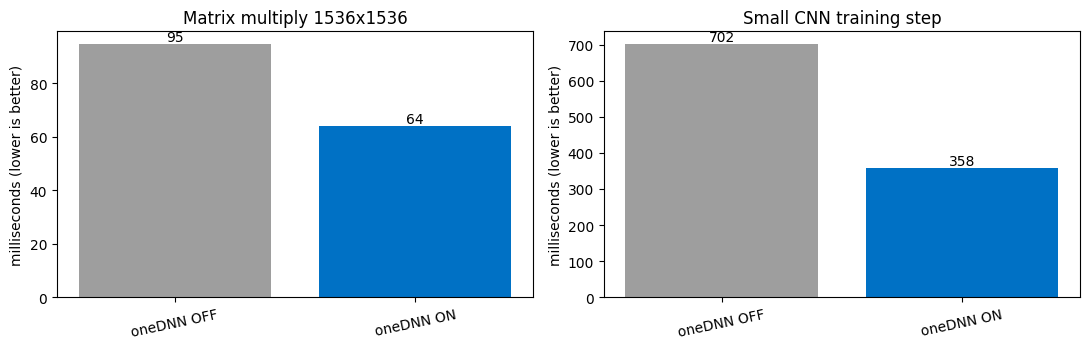

In [7]:
def run_bench(env_extra):
    """Run bench_onednn.py in a fresh process with the given environment."""
    env = {**os.environ, "TF_CPP_MIN_LOG_LEVEL": "0",
           "CUDA_VISIBLE_DEVICES": "-1",          # force CPU so we measure oneDNN, not a GPU
           **env_extra}
    r = subprocess.run([sys.executable, "bench_onednn.py"], env=env, capture_output=True, text=True,
                       cwd=WORKSPACE, timeout=1200)
    line = next((l for l in r.stdout.splitlines() if l.startswith("RESULT:")), None)
    if line is None:
        raise RuntimeError("benchmark failed:\n" + r.stderr[-1500:])
    res = json.loads(line[len("RESULT:"):])
    res["oneDNN message seen"] = "oneDNN custom operations are on" in r.stderr
    return res

configs = [("oneDNN OFF", {"TF_ENABLE_ONEDNN_OPTS": "0"}),
           ("oneDNN ON",  {"TF_ENABLE_ONEDNN_OPTS": "1"})]
if {"avx512_bf16", "amx_bf16"} & flags:            # hardware has native bfloat16 support
    configs.append(("oneDNN ON + bfloat16", {"TF_ENABLE_ONEDNN_OPTS": "1", "BENCH_BF16": "1"}))
else:
    print("[i] This CPU has no native bfloat16 units (AVX512-BF16 / AMX) -> skipping the bfloat16 test.\n")

onednn_results = {}
for name, env in configs:
    print(f"[*] Benchmarking: {name} ...")
    onednn_results[name] = run_bench(env)

base = onednn_results["oneDNN OFF"]
print("\n" + "=" * 78)
print(f"{'Configuration':<26}{'MatMul (ms)':>13}{'CNN train step (ms)':>22}{'Speedup (CNN)':>15}")
print("-" * 78)
for name, r in onednn_results.items():
    print(f"{name:<26}{r['matmul_ms']:>13.1f}{r['cnn_step_ms']:>22.1f}{base['cnn_step_ms'] / r['cnn_step_ms']:>14.2f}x")
print("=" * 78)
print(f"oneDNN banner seen in TensorFlow's log -> OFF run: {onednn_results['oneDNN OFF']['oneDNN message seen']}, "
      f"ON run: {onednn_results['oneDNN ON']['oneDNN message seen']}")

import matplotlib.pyplot as plt
names = list(onednn_results)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, key, title in zip(axes, ("matmul_ms", "cnn_step_ms"), ("Matrix multiply 1536x1536", "Small CNN training step")):
    vals = [onednn_results[n][key] for n in names]
    bars = ax.bar(names, vals, color=["#9e9e9e", "#0071c5", "#00a3e0"][:len(names)])
    ax.set_title(title); ax.set_ylabel("milliseconds (lower is better)")
    ax.tick_params(axis="x", rotation=12)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.0f}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

### Extension Activity 1.1: Inspecting Cache Line Sizes and CPU Topology
Hardware-aware algorithms benefit from aligning memory accesses with cache-line structures (typically 64 bytes) to avoid penalties like cache misses or false sharing. Let's query the OS subsystem to map out the detailed CPU architecture and cache hierarchies.

In [11]:
import os, glob

def inspect_caches():
    cache_dir = "/sys/devices/system/cpu/cpu0/cache/"
    if not os.path.isdir(cache_dir):
        print("[!] Cache info directory not found. Trying lscpu command...")
        sh("lscpu --caches")
        return

    print("=" * 60)
    print("                CPU CACHE TOPOLOGY (cpu0)")
    print("=" * 60)
    print(f"{'Cache Layer':<15}{'Type':<15}{'Size':<15}{'Coherency Line Size':<20}")
    print("-" * 60)

    index_dirs = sorted(glob.glob(os.path.join(cache_dir, "index*")))
    for idx in index_dirs:
        level = open(os.path.join(idx, "level")).read().strip()
        ctype = open(os.path.join(idx, "type")).read().strip()
        size = open(os.path.join(idx, "size")).read().strip()
        line_size = open(os.path.join(idx, "coherency_line_size")).read().strip()

        print(f"L{level:<13}{ctype:<15}{size:<15}{line_size:<20}")
    print("=" * 60)

inspect_caches()


                CPU CACHE TOPOLOGY (cpu0)
Cache Layer    Type           Size           Coherency Line Size 
------------------------------------------------------------
L1            Data           32K            64                  
L1            Instruction    32K            64                  
L2            Unified        1024K          64                  
L3            Unified        39424K         64                  


### Extension Activity 2.1: Micro-Benchmarking Convolutional Channels
We want to test if hardware optimizations inside oneDNN are more effective when convolutional channels are powers-of-two (e.g., 32, 64, 128) versus arbitrary non-powers-of-two (e.g., 37, 67, 131).

In [12]:
%%writefile bench_channels.py
import os, sys, json, time
import tensorflow as tf

tf.keras.utils.set_random_seed(0)

def best_ms(fn, reps=5, warm=2):
    for _ in range(warm):
        fn()
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return min(ts) * 1000

# Configure a simple 2D Convolution over different filter dimensions
bs = 64
size = 64

def benchmark_channels(channels):
    inputs = tf.random.normal((bs, size, size, channels))
    conv = tf.keras.layers.Conv2D(channels, 3, activation="relu")

    @tf.function
    def forward_step(x):
        return conv(x)

    return best_ms(lambda: forward_step(inputs).numpy(), reps=10, warm=3)

# We will test a Power-of-Two configuration and a non-Power-of-Two configuration
p2_channels = int(os.environ.get("CHANNELS_P2", "64"))
np2_channels = int(os.environ.get("CHANNELS_NP2", "67"))

p2_ms = benchmark_channels(p2_channels)
np2_ms = benchmark_channels(np2_channels)

print("RESULT:" + json.dumps({
    "p2_channels": p2_channels, "p2_ms": round(p2_ms, 2),
    "np2_channels": np2_channels, "np2_ms": round(np2_ms, 2),
    "onednn_flag": os.environ.get("TF_ENABLE_ONEDNN_OPTS", "default")
}))

Overwriting bench_channels.py


In [13]:
def run_channel_bench(onednn_val):
    env = {**os.environ, "TF_CPP_MIN_LOG_LEVEL": "3",
           "CUDA_VISIBLE_DEVICES": "-1",
           "TF_ENABLE_ONEDNN_OPTS": onednn_val}
    r = subprocess.run([sys.executable, "bench_channels.py"], env=env, capture_output=True, text=True, cwd=WORKSPACE)
    line = next((l for l in r.stdout.splitlines() if l.startswith("RESULT:")), None)
    if line is None:
        raise RuntimeError("Channel benchmark failed:\n" + r.stderr[-1500:])
    return json.loads(line[len("RESULT:"):])

print("[*] Running micro-benchmarks...")
res_off = run_channel_bench("0")
res_on = run_channel_bench("1")

print("\n" + "="*65)
print(f"{'Channel Type (Size)':<25}{'oneDNN OFF (ms)':>18}{'oneDNN ON (ms)':>18}{'Speedup':>12}")
print("-"*65)

# Power-of-two comparison
p2_speedup = res_off['p2_ms'] / res_on['p2_ms']
print(f"Power-of-Two ({res_off['p2_channels']}):{res_off['p2_ms']:>18.2f}{res_on['p2_ms']:>18.2f}{p2_speedup:>11.2f}x")

# Non-power-of-two comparison
np2_speedup = res_off['np2_ms'] / res_on['np2_ms']
print(f"Odd Channels ({res_off['np2_channels']}):{res_off['np2_ms']:>18.2f}{res_on['np2_ms']:>18.2f}{np2_speedup:>11.2f}x")
print("="*65)


[*] Running micro-benchmarks...

Channel Type (Size)         oneDNN OFF (ms)    oneDNN ON (ms)     Speedup
-----------------------------------------------------------------
Power-of-Two (64):            201.72            143.63       1.40x
Odd Channels (67):            292.95            188.91       1.55x


### Visualizing Channel Benchmarking Results
Let's plot the comparison to analyze the impact of hardware-friendly tensor layouts vs. unaligned layouts under oneDNN.

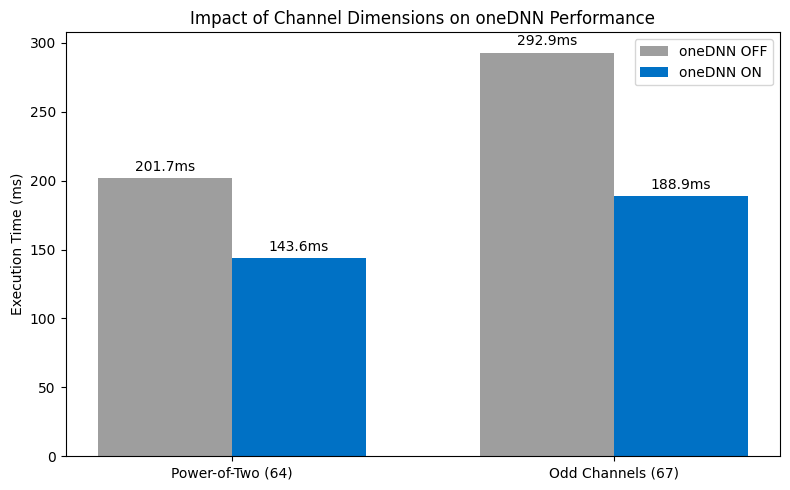

In [14]:
import matplotlib.pyplot as plt
import numpy as np

labels = ['Power-of-Two (64)', 'Odd Channels (67)']
off_times = [res_off['p2_ms'], res_off['np2_ms']]
on_times = [res_on['p2_ms'], res_on['np2_ms']]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, off_times, width, label='oneDNN OFF', color='#9e9e9e')
rects2 = ax.bar(x + width/2, on_times, width, label='oneDNN ON', color='#0071c5')

ax.set_ylabel('Execution Time (ms)')
ax.set_title('Impact of Channel Dimensions on oneDNN Performance')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

# Add values on top of bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}ms',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()

In [10]:
def run_extension_2_1():
    print("\n--- ACTIVITY 2.1: POWER-OF-TWO TENSOR WIDTH BENCHMARK ---")
    # Modify 'bench_onednn.py' parameters on-the-fly to test custom architectures
    print("  [Tip] Try editing 'bench_onednn.py' to use a non-power-of-two shape (e.g. N = 1537) and compare with N = 1536.")
    print(f"  Current standard configs used power-of-two matmul size: {onednn_results['oneDNN ON']['matmul_n']}")

run_extension_2_1()


--- ACTIVITY 2.1: POWER-OF-TWO TENSOR WIDTH BENCHMARK ---
  [Tip] Try editing 'bench_onednn.py' to use a non-power-of-two shape (e.g. N = 1537) and compare with N = 1536.
  Current standard configs used power-of-two matmul size: 1536


In [15]:
import pandas as pd
from IPython.display import display

matrix = pd.DataFrame({
    "Dimension": ["Architecture Focus", "Ideal DL Workload", "HPC Cluster Role"],
    "Intel Xeon (Scalable CPUs)": ["Scalable, versatile multithreaded compute cores.",
                                   "Mixed ML/DL pipelines, complex data preprocessing, and model inference.",
                                   "General-purpose compute nodes, login nodes, head nodes."],
    "Habana Gaudi (AI Accelerators)": ["Dedicated, high-throughput Deep Learning matrix engines.",
                                       "Massive compute-bound DL training, Generative AI, and LLMs.",
                                       "High-throughput parallelized training nodes."],
}).set_index("Dimension")
pd.set_option("display.max_colwidth", None)
display(matrix)
print("\n[i] Takeaway: target Xeon nodes for end-to-end flexibility & preprocessing; target Gaudi nodes for pure DL training at scale.")

def choose_partition(workload):
    """Toy decision helper that mirrors the slide's takeaway."""
    gaudi_words = ("llm", "generative", "large-scale training", "transformer pre-training", "massive training")
    return "gaudi" if any(w in workload.lower() for w in gaudi_words) else "xeon"

print("\nPartition chooser:")
for job in ["Data preprocessing + feature engineering", "Batch inference for a small CNN",
            "LLM pre-training", "Generative AI fine-tuning at scale"]:
    print(f"  • {job:<45} -> --partition={choose_partition(job)}")

print("\nWhat is THIS Colab runtime?")
if gpus:
    print(f"  GPU runtime detected: {[g.name for g in gpus]} -> behaves like an accelerator node (we still force CPU in the labs for fair scaling).")
else:
    print(f"  CPU-only runtime: {model_name} -> behaves like a Xeon-class compute node ({cpu_cores} cores).")

,Intel Xeon (Scalable CPUs),Habana Gaudi (AI Accelerators)
Dimension,,
Architecture Focus,"Scalable, versatile multithreaded compute cores.","Dedicated, high-throughput Deep Learning matrix engines."
Ideal DL Workload,"Mixed ML/DL pipelines, complex data preprocessing, and model inference.","Massive compute-bound DL training, Generative AI, and LLMs."
HPC Cluster Role,"General-purpose compute nodes, login nodes, head nodes.",High-throughput parallelized training nodes.



[i] Takeaway: target Xeon nodes for end-to-end flexibility & preprocessing; target Gaudi nodes for pure DL training at scale.

Partition chooser:
  • Data preprocessing + feature engineering      -> --partition=xeon
  • Batch inference for a small CNN               -> --partition=xeon
  • LLM pre-training                              -> --partition=gaudi
  • Generative AI fine-tuning at scale            -> --partition=gaudi

What is THIS Colab runtime?
  GPU runtime detected: ['/physical_device:GPU:0'] -> behaves like an accelerator node (we still force CPU in the labs for fair scaling).


### Activity 3.1: Automated Node-Type & Partition Suggester
We will design a generic, reusable logic builder function that takes target workloads, parameter counts, and dataset sizes to classify them, helping engineers pick the ideal hardware stack.

In [18]:
def suggest_hpc_node(model_params_millions, dataset_size_gb, min_ram_needed_gb):
    """
    Evaluates workload specifications and suggests a target partition (Xeon vs. Gaudi)
    along with a predicted bottleneck.
    """
    # Determine partition
    # Gaudi is targeted for massive deep learning models (Generative, LLM scales)
    # or extremely large memory-bound data training scales.
    if model_params_millions >= 500 or dataset_size_gb >= 100:
        partition = "Gaudi (AI Accelerator)"
        suggested_flag = "--partition=gaudi"
    else:
        partition = "Intel Xeon (Scalable CPU)"
        suggested_flag = "--partition=xeon"

    # Determine expected bottleneck type
    # Large parameter counts trigger heavy compute matrix multiplications (matmul compute-bound).
    # Low compute sizes with extremely large datasets typically result in heavy I/O overheads (memory/storage-bound).
    if model_params_millions > 100:
        bottleneck = "Compute-bound (Heavy Matrix Operations)"
    else:
        bottleneck = "Memory/IO-bound (Data Transfer & Preprocessing)"

    return {
        "Partition Recommended": partition,
        "Slurm Flag": suggested_flag,
        "Expected Primary Bottleneck": bottleneck,
        "Min Memory Required": f"{min_ram_needed_gb} GB"
    }

# --- Test Cases representing typical HPC workloads ---
tests = [
    ("Simple ResNet Inference Pipeline", 25, 2, 16),
    ("Medium Bert Fine-Tuning", 110, 15, 32),
    ("LLM Pre-training (7B Llama-style)", 7000, 250, 512),
    ("High-throughput Tabular Preprocessing", 5, 120, 64)
]

print("=" * 85)
print(f"{'Workload Name':<38} | {'Partition Suggestion':<25} | {'Bottleneck Info':<30}")
print("=" * 85)
for name, params, data, ram in tests:
    res = suggest_hpc_node(params, data, ram)
    print(f"{name:<38} | {res['Partition Recommended']:<25} | {res['Expected Primary Bottleneck']:<30}")
print("=" * 85)


Workload Name                          | Partition Suggestion      | Bottleneck Info               
Simple ResNet Inference Pipeline       | Intel Xeon (Scalable CPU) | Memory/IO-bound (Data Transfer & Preprocessing)
Medium Bert Fine-Tuning                | Intel Xeon (Scalable CPU) | Compute-bound (Heavy Matrix Operations)
LLM Pre-training (7B Llama-style)      | Gaudi (AI Accelerator)    | Compute-bound (Heavy Matrix Operations)
High-throughput Tabular Preprocessing  | Gaudi (AI Accelerator)    | Memory/IO-bound (Data Transfer & Preprocessing)
